# GRU generation huis




In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import time
from pathlib import Path
import sys
# Gebruik de GPU als die er is, anders de CPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


# Data inladen

In [24]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
split = pd.read_parquet(ROOT / "prepared_data" / "model_split.parquet").iloc[0]
sys.path.insert(0, str(ROOT))
from exploration.open_meteo_weer_merge import haal_modeldata_op
df = haal_modeldata_op()
huis_consumption = df[(df['location'] == 'huis') & (df['target_type'] == 'consumption')]
huis_consumption = huis_consumption.dropna(subset=['pow_imputed'])
huis_consumption = huis_consumption[(huis_consumption["timestamp"] >= split["train_start"]) & (huis_consumption["timestamp"] < split["test_end"])].reset_index(drop=True)


## voorspel instellingen

In [25]:
huis_consumption.columns

Index(['timestamp', 'location', 'target_type', 'pow_w', 'pow_imputed',
       'is_observed', 'is_conflict', 'is_imputed', 'impute_methode',
       'temperature_2m', 'shortwave_radiation', 'relative_humidity_2m',
       'timestamp_nl', 'uur_sin', 'uur_cos', 'week_sin', 'week_cos'],
      dtype='object')

In [26]:
stap_per_dag = 24 * 12               # 288 per dag

aantal_dagen_input = 7               # aantal dagen voor input
input_len = aantal_dagen_input * stap_per_dag

aantal_dagen_forecast = 3            # =aantal dagen voorspelling
horizon = aantal_dagen_forecast * stap_per_dag

stride = 12                          # het venster schuift 12 stappen (1 uur) per voorbeeld op

FEATURE_COLS = ['pow_imputed', 'uur_sin', 'uur_cos', 'week_sin', 'week_cos','temperature_2m', 'shortwave_radiation','relative_humidity_2m']
TARGET_COL = 'pow_imputed'                                 

In [27]:
huis_consumption[FEATURE_COLS].isnull().sum()

pow_imputed             0
uur_sin                 0
uur_cos                 0
week_sin                0
week_cos                0
temperature_2m          0
shortwave_radiation     0
relative_humidity_2m    0
dtype: int64

In [28]:
n_features = len(FEATURE_COLS)
target_idx = FEATURE_COLS.index(TARGET_COL)

In [29]:
target = "pow_imputed"

corr = huis_consumption[FEATURE_COLS].corr(numeric_only=True)

print(corr[target].sort_values(ascending=False))

pow_imputed             1.000000
shortwave_radiation     0.389530
temperature_2m          0.116747
week_sin                0.011940
week_cos                0.005056
uur_sin                -0.171755
uur_cos                -0.244650
relative_humidity_2m   -0.274843
Name: pow_imputed, dtype: float64


## chronologisch splisen

In [30]:
values = huis_consumption[FEATURE_COLS].values

n = len(values)
tijd = pd.to_datetime(huis_consumption["timestamp"])
i_train = tijd.searchsorted(split["train_end"])
i_val = tijd.searchsorted(split["test_start"])

train_raw = values[:i_train]
val_raw = values[i_train:i_val]
test_raw = values[i_val:]

## normaliseren

In [31]:
train_mean = train_raw.mean(axis=0)
train_std = train_raw.std(axis=0)

train = (train_raw - train_mean) / train_std
val = (val_raw - train_mean) / train_std
test = (test_raw - train_mean) / train_std

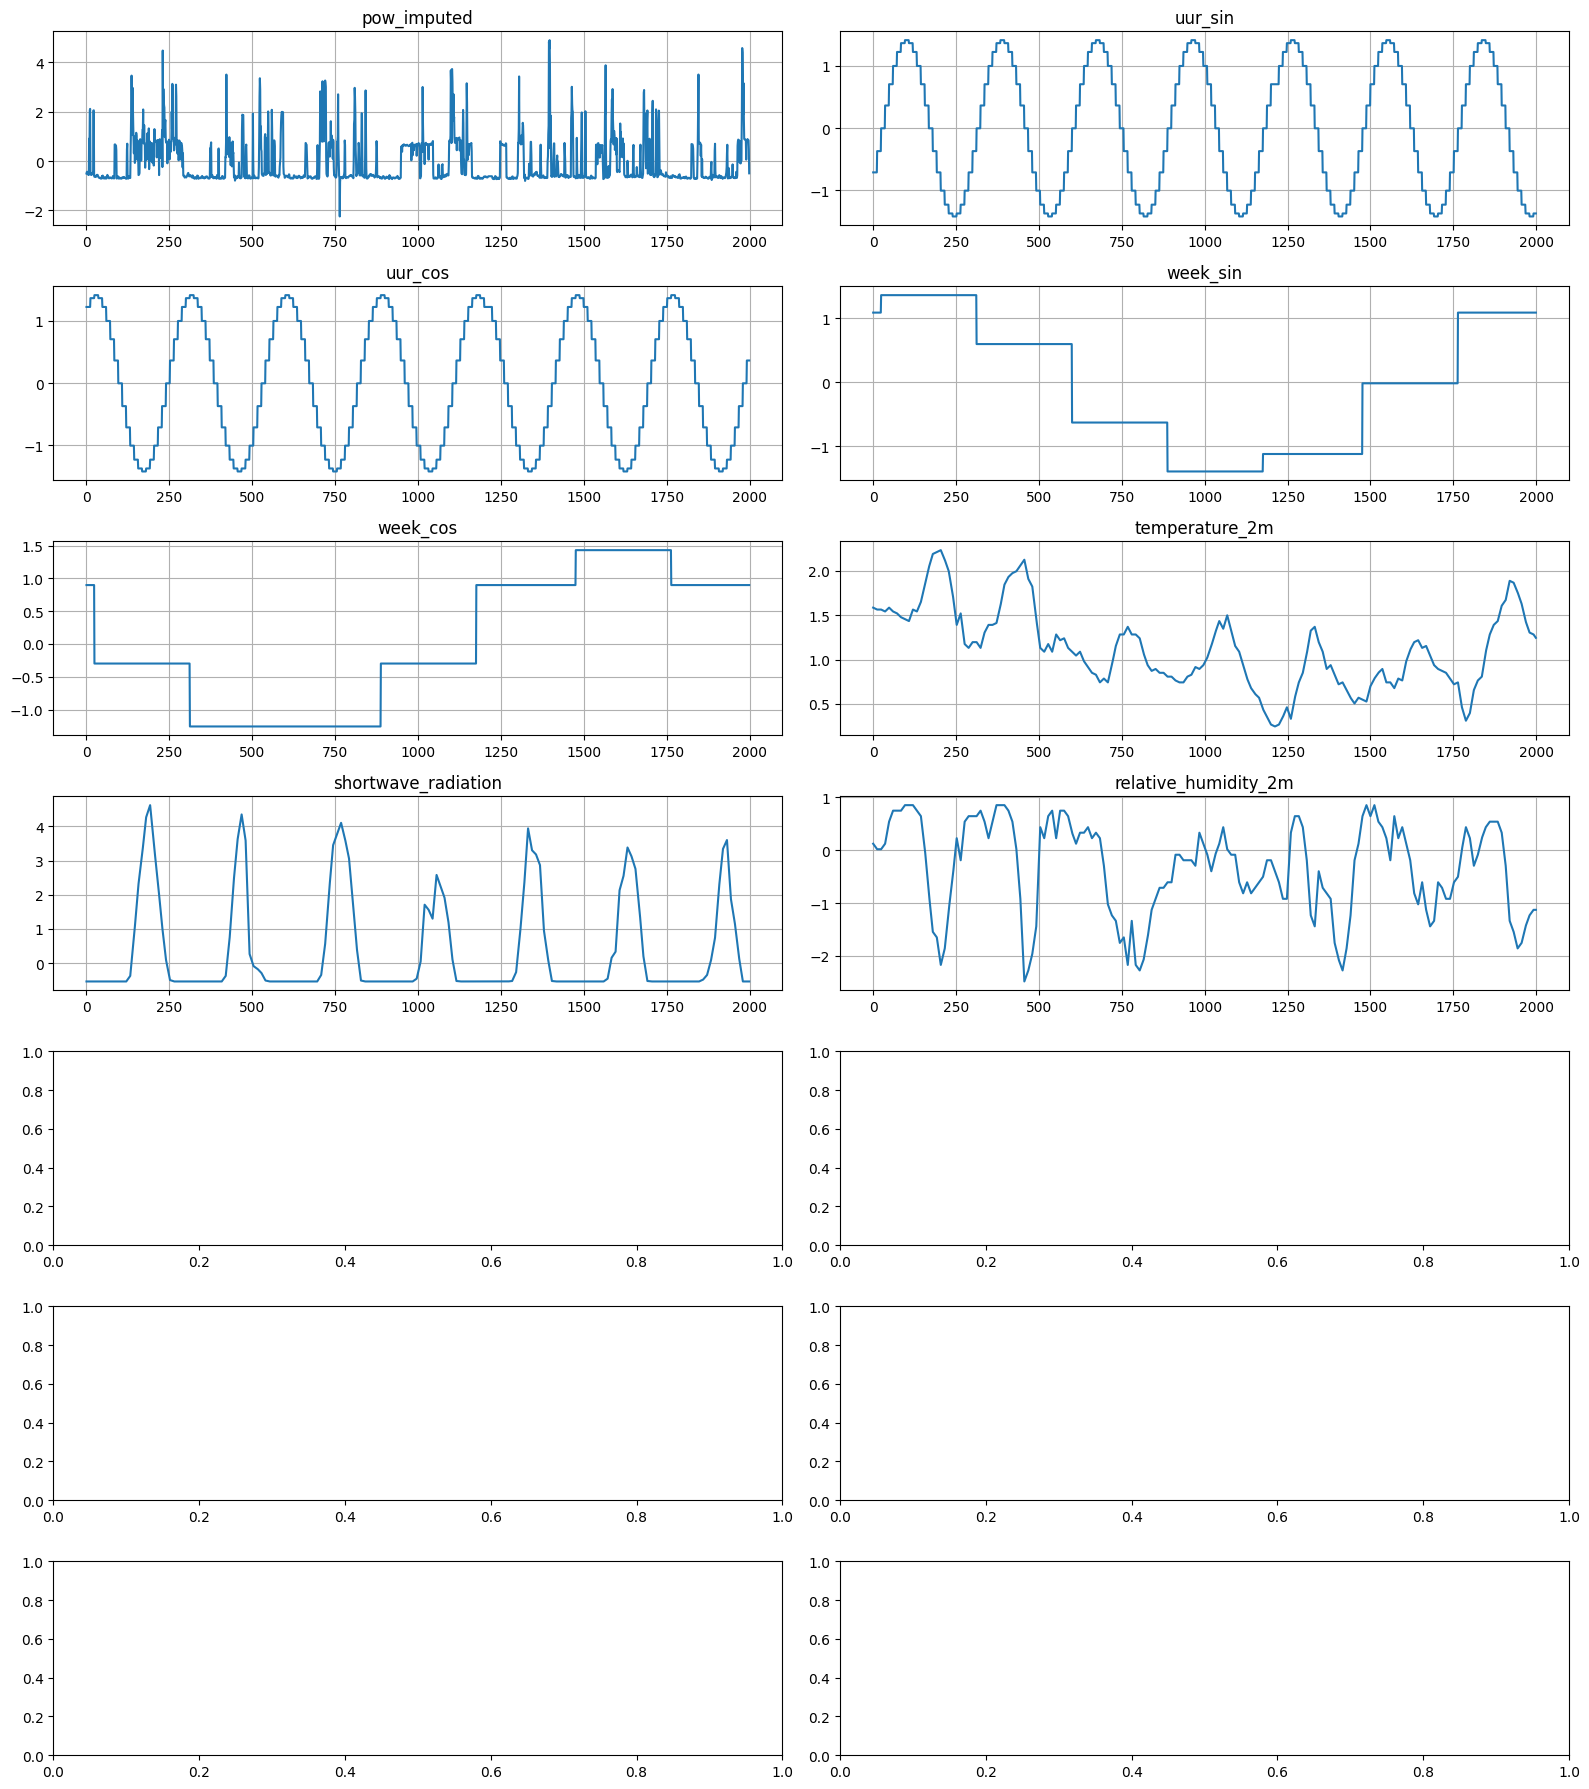

In [32]:
# features na normaliseren
fig, ax = plt.subplots(7, 2, figsize=(16, 18))
ax = ax.flatten()

for i, feature in enumerate(FEATURE_COLS):
    ax[i].plot(train[:2000, i])
    ax[i].set_title(feature)
    ax[i].grid(True)

plt.tight_layout()
plt.show()

In [33]:
class WindowDataset(Dataset):

    def __init__(self, data, input_len, horizon, target_idx, stride):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.input_len = input_len
        self.horizon = horizon
        self.target_idx = target_idx

        # Hoeveel vensters passen er in de data? Elk venster heeft input_len + horizon stappen nodig
        n_vensters = len(data) - input_len - horizon + 1
        self.starts = range(0, max(n_vensters, 0), stride)

    # Bereken het aantal voorbeelden
    def __len__(self):
        return len(self.starts)

    # Haal voorbeeld nummer idx op
    def __getitem__(self, idx):
        s = self.starts[idx]
        x = self.data[s : s + self.input_len]                                   # geschiedenis
        y = self.data[s + self.input_len : s + self.input_len + self.horizon,   # toekomst,
                      self.target_idx]                                          # alleen de target
        return x, y

Creeer dataset voor de training, validatie en test data.

In [34]:
train_dataset = WindowDataset(train, input_len, horizon, target_idx, stride)
val_dataset = WindowDataset(val, input_len, horizon, target_idx, stride)
test_dataset = WindowDataset(test, input_len, horizon, target_idx, stride)

print("aantal voorbeelden | train:", len(train_dataset), "| val:", len(val_dataset), "| test:", len(test_dataset))

aantal voorbeelden | train: 2678 | val: 386 | test: 385


Creeer DataLoader 

In [35]:
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

## model

## training loop


In [36]:
hidden_sizes = [64,64]             # het aantal getallen van hidden size staat gelijk aan het aantal lagen 
dropout = 0.2                  
learning_rate = 1e-3
output_size = horizon           

class Customgru(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, dropout=0.0):
        super().__init__()

        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout)

        prev_size = input_size
        for h in hidden_sizes:
            self.layers.append(
                nn.GRU(input_size=prev_size,
                        hidden_size=h,
                        num_layers=1,
                        batch_first=True)
            )
            prev_size = h

        self.fc = nn.Linear(hidden_sizes[-1], output_size)

    def forward(self, x):
        out = x
        for lstm in self.layers:
            out, _ = lstm(out)
            out = self.dropout(out)

        out = out[:, -1, :]
        return self.fc(out)


model = Customgru(
    input_size=n_features,
    hidden_sizes=hidden_sizes,
    output_size=horizon,
    dropout=0.2
).to(DEVICE)

criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

print("CUSTOM gru |", sum(p.numel() for p in model.parameters()), "parameters")


CUSTOM gru | 95328 parameters


In [37]:
n_epochs = 20

train_loss_list = []
val_loss_list = []
epoch_time_list = []

std_target = train_std[target_idx]                

if DEVICE == "cuda":
    torch.cuda.synchronize()
# start tijd
start_totaal = time.perf_counter()                   

for epoch in range(n_epochs):
    start_epoch = time.perf_counter()
    # Trainen
    model.train()
    running_loss = 0.0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)

        optimizer.zero_grad()
        output = model(inputs)
        loss = criterion(output, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.shape[0]

    train_loss = running_loss / len(train_dataset)
    train_loss_list.append(train_loss)

    # Validatie
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            loss = criterion(model(inputs), targets)
            val_loss += loss.item() * targets.shape[0]
    val_loss = val_loss / len(val_dataset)
    val_loss_list.append(val_loss)

    if DEVICE == "cuda":
        torch.cuda.synchronize()
    # epoch tijd

    epoch_tijd = time.perf_counter() - start_epoch    
    epoch_time_list.append(epoch_tijd)

    print(f"Epoch {epoch+1}/{n_epochs}, "
          f"train loss: {train_loss:.4f} (echte MAE: {train_loss * std_target:.1f}), "   
          f"validation loss: {val_loss:.4f} (echte MAE: {val_loss * std_target:.1f}), " )
# totale tijd 
totale_tijd = time.perf_counter() - start_totaal      
print(f"\nTotale trainingstijd: {totale_tijd:.1f}s ({totale_tijd/60:.1f} min)")
print(f"Gemiddeld per epoch: {np.mean(epoch_time_list):.1f}s")

Epoch 1/20, train loss: 0.6794 (echte MAE: 476.2), validation loss: 0.8708 (echte MAE: 610.3), 
Epoch 2/20, train loss: 0.6371 (echte MAE: 446.5), validation loss: 0.8784 (echte MAE: 615.6), 
Epoch 3/20, train loss: 0.6326 (echte MAE: 443.4), validation loss: 0.8710 (echte MAE: 610.4), 
Epoch 4/20, train loss: 0.6298 (echte MAE: 441.4), validation loss: 0.8779 (echte MAE: 615.3), 
Epoch 5/20, train loss: 0.6272 (echte MAE: 439.6), validation loss: 0.8778 (echte MAE: 615.2), 
Epoch 6/20, train loss: 0.6249 (echte MAE: 438.0), validation loss: 0.8767 (echte MAE: 614.4), 
Epoch 7/20, train loss: 0.6241 (echte MAE: 437.4), validation loss: 0.8722 (echte MAE: 611.3), 
Epoch 8/20, train loss: 0.6230 (echte MAE: 436.6), validation loss: 0.8827 (echte MAE: 618.7), 
Epoch 9/20, train loss: 0.6221 (echte MAE: 436.0), validation loss: 0.8754 (echte MAE: 613.5), 
Epoch 10/20, train loss: 0.6215 (echte MAE: 435.6), validation loss: 0.8816 (echte MAE: 617.9), 
Epoch 11/20, train loss: 0.6209 (echte 

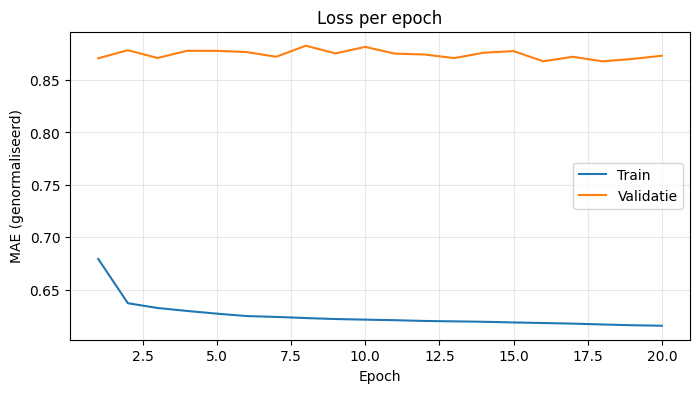

In [38]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_epochs + 1), train_loss_list, label='Train')
plt.plot(range(1, n_epochs + 1), val_loss_list, label='Validatie')
plt.xlabel('Epoch')
plt.ylabel('MAE (genormaliseerd)')
plt.title('Loss per epoch')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

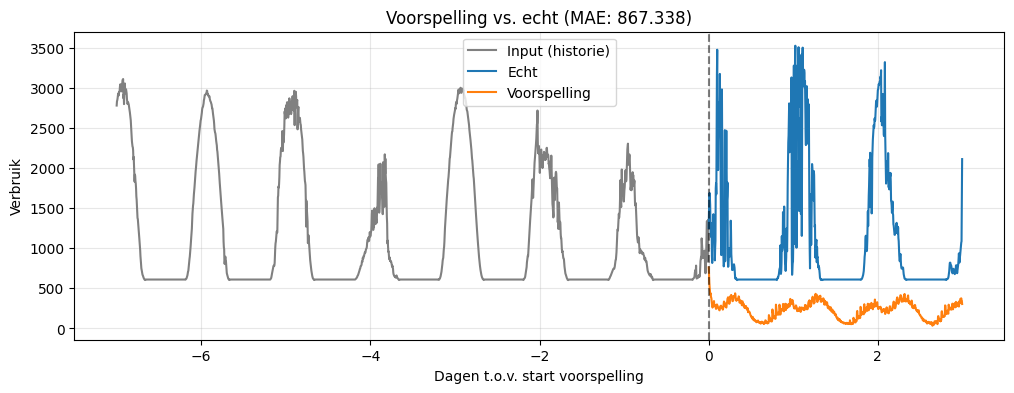

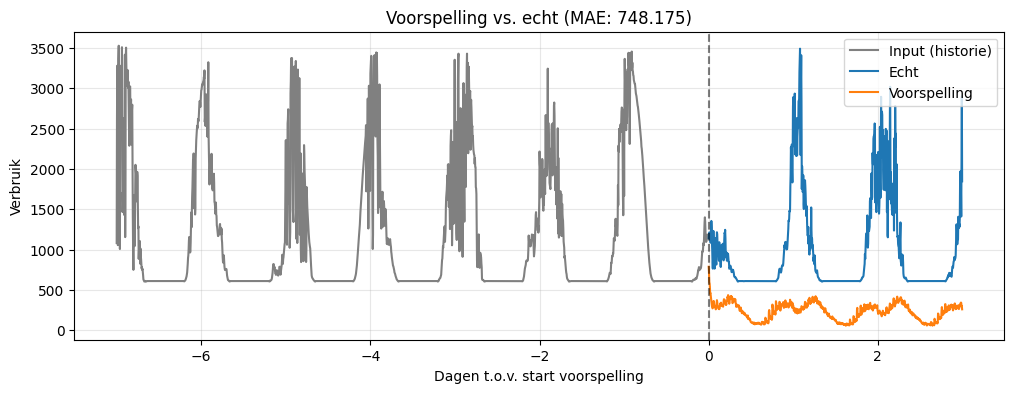

In [39]:
def plot_voorspelling(dataset, idx=0, titel='Voorspelling vs. echt'):
    model.eval()
    x, y = dataset[idx]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(DEVICE)).cpu().numpy().flatten()

    # terug naar originele eenheid (de-normaliseren)
    m, s = train_mean[target_idx], train_std[target_idx]
    hist = x[:, target_idx].numpy() * s + m
    echt = y.numpy() * s + m
    pred = pred * s + m

    mae = np.abs(pred - echt).mean()

    t_hist = np.arange(-input_len, 0) / stap_per_dag     # x-as in dagen
    t_fc = np.arange(horizon) / stap_per_dag

    plt.figure(figsize=(12, 4))
    plt.plot(t_hist, hist, color='grey', label='Input (historie)')
    plt.plot(t_fc, echt, label='Echt')
    plt.plot(t_fc, pred, label='Voorspelling')
    plt.axvline(0, color='black', linestyle='--', alpha=0.5)
    plt.xlabel('Dagen t.o.v. start voorspelling')
    plt.ylabel('Verbruik')
    plt.title(f'{titel} (MAE: {mae:.3f})')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_voorspelling(test_dataset, idx=0)
plot_voorspelling(test_dataset, idx=len(test_dataset) // 2)   # een ander moment

MAE totaal: 908 W
Dag 1: 885 W
Dag 2: 917 W
Dag 3: 923 W


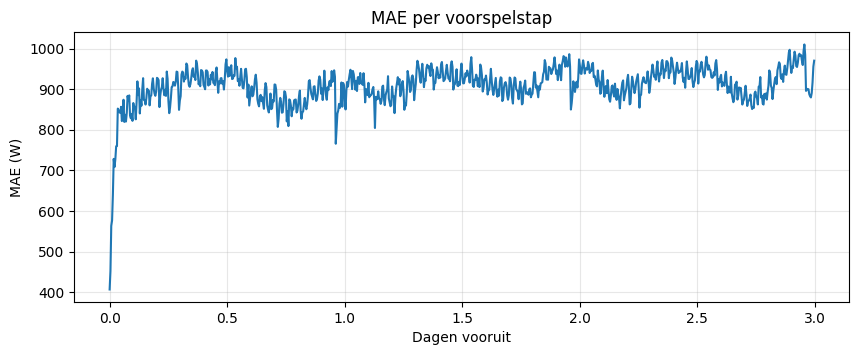

In [40]:
model.eval()
fouten = []
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        fouten.append((model(inputs) - targets).abs().cpu())
fouten = torch.cat(fouten).numpy() * std_target     

mae_per_stap = fouten.mean(axis=0)
print(f"MAE totaal: {fouten.mean():.0f} W")
for d in range(aantal_dagen_forecast):
    s = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
    print(f"Dag {d+1}: {mae_per_stap[s].mean():.0f} W")

plt.figure(figsize=(10, 3.5))
plt.plot(np.arange(horizon) / stap_per_dag, mae_per_stap)
plt.xlabel('Dagen vooruit')
plt.ylabel('MAE (W)')
plt.title('MAE per voorspelstap')
plt.grid(alpha=0.3)
plt.show()

## Resultaten opslaan
---
- Zelfde format als de andere modellen, opgeslagen in `models/results/`
- MAE in Watt op alle testvensters (elk uur een nieuwe forecast van 3 dagen)
- Persistence dag = zelfde tijdstip van de meest recente bekende dag, persistence week = zelfde tijdstip een week eerder

In [ ]:
from pathlib import Path

MODEL_NAAM = "GRU (weer)"
NOTEBOOK = "gru_consumption_huis_weer"
TARGET = "consumption"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
RESULTS_DIR = ROOT / "models" / "results"
MODEL_DIR = ROOT / "models" / "saved_models"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

#Voorspellen op alle testvensters, test_loader schudt niet dus de volgorde klopt
model.eval()
preds, targets_norm = [], []
if DEVICE == "cuda":
    torch.cuda.synchronize()
t0 = time.perf_counter()
with torch.no_grad():
    for inputs, targets in test_loader:
        preds.append(model(inputs.to(DEVICE)).cpu())
        targets_norm.append(targets)
if DEVICE == "cuda":
    torch.cuda.synchronize()
voorspeltijd = time.perf_counter() - t0

m, s = train_mean[target_idx], train_std[target_idx]
pred_test = torch.cat(preds).numpy() * s + m

#Echte waarden en baselines direct uit de reeks in Watt
y_arr = huis_consumption[TARGET_COL].to_numpy()
test_origins = i_val + input_len + np.array(test_dataset.starts)
h = np.arange(horizon)
t = test_origins[:, None] + h[None, :]
echt_test = y_arr[t]
base_dag = y_arr[t - stap_per_dag * (h // stap_per_dag + 1)]
base_week = y_arr[t - input_len]
assert np.allclose(torch.cat(targets_norm).numpy() * s + m, echt_test, atol=1.0), "testvensters komen niet overeen"


def scores(pred, echt):
    fout = pred - echt
    res = {"MAE": np.abs(fout).mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for d in range(aantal_dagen_forecast):
        sl = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
        res[f"MAE dag {d+1}"] = np.abs(fout[:, sl]).mean()
    #Rolling validation: elke dag een nieuwe forecast
    dagelijks = slice(None, None, stap_per_dag // stride)
    res["rolling MAE"] = np.abs(fout[dagelijks]).mean(axis=1).mean()
    res["rolling RMSE"] = np.sqrt((fout[dagelijks] ** 2).mean(axis=1)).mean()
    return res

alle = {MODEL_NAAM: pred_test, "Persistence dag": base_dag, "Persistence week": base_week}
resultaten = pd.DataFrame({naam: scores(pred, echt_test) for naam, pred in alle.items()}).T
resultaten.loc[MODEL_NAAM, "trainingstijd (s)"] = totale_tijd
resultaten.loc[MODEL_NAAM, "voorspeltijd (s)"] = voorspeltijd
resultaten = resultaten.round(1)

#Model opslaan en bestandsgrootte meten
pad = MODEL_DIR / f"{NOTEBOOK}.pt"
torch.save(model.state_dict(), pad)
resultaten.loc[MODEL_NAAM, "modelgrootte (MB)"] = round(pad.stat().st_size / 1e6, 3)

KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
            "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
            "modelgrootte (MB)"]
tijden = pd.to_datetime(huis_consumption["timestamp"])
resultaten["notebook"] = NOTEBOOK
resultaten["locatie"] = "huis"
resultaten["target"] = TARGET
resultaten["resolutie"] = "5 min"
resultaten["testperiode"] = f"{tijden.iloc[i_val]:%Y-%m-%d} t/m {tijden.iloc[-1]:%Y-%m-%d}"
resultaten = resultaten.reindex(columns=KOLOMMEN)
resultaten.to_csv(RESULTS_DIR / f"{NOTEBOOK}.csv")
resultaten

,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
GRU (weer),gru_consumption_huis_weer,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,613.5,990.4,617.4,610.6,612.6,626.0,983.7,0.0,0.1,0.388
Persistence dag,gru_consumption_huis_weer,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,305.0,577.7,295.0,304.0,316.1,303.0,568.0,NaN,NaN,NaN
Persistence week,gru_consumption_huis_weer,huis,consumption,5 min,2026-03-18 t/m 2026-04-13,292.7,557.7,291.4,289.5,297.3,293.6,552.9,NaN,NaN,NaN
